## Area of plates simulation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

We image producing many plates and measuring the width and length of each plate.

Instead of doing this in real life, we simulate :)

We store our simulated data as we would store real data (here in a pandas DataFrame).

In [2]:
np.random.seed(2242)

In [3]:
# number of simulations:
k = 10000

In [4]:
# simulating width and length from normal distributions:

simulation_data = pd.DataFrame({
 'length': stats.norm.rvs(size=k, loc=2, scale=0.01),
 'width':  stats.norm.rvs(size=k, loc=3, scale=0.02)
 })

print(simulation_data.head())

     length     width
0  2.009985  3.012217
1  2.001759  3.002237
2  1.992384  2.989372
3  1.988568  3.021869
4  2.012836  2.976332


In [5]:
# for each simulated plate we calculate the area and store this (as a new column) in our DataFrame:
simulation_data['area'] = simulation_data['length'] * simulation_data['width']

print(simulation_data.head())

     length     width      area
0  2.009985  3.012217  6.054512
1  2.001759  3.002237  6.009755
2  1.992384  2.989372  5.955977
3  1.988568  3.021869  6.009192
4  2.012836  2.976332  5.990868


In [6]:
# Compute mean and standard deviation from simulated plate areas:
print(simulation_data['area'].mean())      # mean area
print(simulation_data['area'].std(ddof=1)) # sample standard deviation of area
print(simulation_data['area'].var(ddof=1)) # sample variance of area

5.999828782091479
0.05049830256379191
0.0025500785618242728


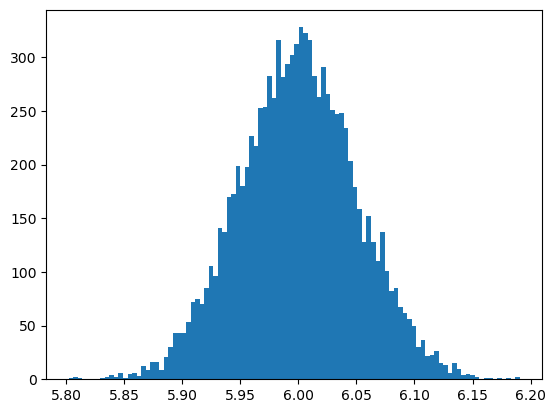

In [7]:
# Lets plot the distribution of simulated plate areas:
plt.hist(simulation_data['area'], bins=100)
plt.show()

What do you think about this distribution? (describe in own words)

In [8]:
# how many values deviate by more than 0.10 from 6.00 m2 ?

# plates that have an area below 5.90 are very "small" (indicated by a boolean variable)
simulation_data['small'] = simulation_data['area'] < 5.90

# plates that have an area above 6.10 are very "large" (indicated by a boolean variable)
simulation_data['large'] = simulation_data['area'] > 6.10

print(simulation_data.head())

     length     width      area  small  large
0  2.009985  3.012217  6.054512  False  False
1  2.001759  3.002237  6.009755  False  False
2  1.992384  2.989372  5.955977  False  False
3  1.988568  3.021869  6.009192  False  False
4  2.012836  2.976332  5.990868  False  False


In [9]:
# Showing an example of a row that has a "True" value:
print(simulation_data.iloc[43:48])

      length     width      area  small  large
43  2.001597  2.988288  5.981349  False  False
44  1.993024  3.017522  6.013994  False  False
45  2.028156  3.011995  6.108797  False   True
46  1.991349  2.979674  5.933570  False  False
47  1.999831  2.976588  5.952673  False  False


In [10]:
# how many values deviate by more than 0.10 from 6m2 ? 
# these are the very "small" plus the very "large":

# In Python we can simply add "True" (1) and "False" (0) values:
print(np.sum(simulation_data['small']) + np.sum(simulation_data['large']))

# same result as a fraction of total number os simulations:
print((np.sum(simulation_data['small']) + np.sum(simulation_data['large']))/k)

477
0.0477


approx 4-5% of plates deviate more than 0.10 from 6m2

### Other probabilities (from unknown distributions)

In [11]:
# Imagine the plates have a thickness between 0.95cm and 1.05cm

# Simulate the thickness of each plate (assume the thickness is independent of width and length)
simulation_data['thickness'] = stats.uniform.rvs(size=k, loc=0.0095, scale=0.001)

print(simulation_data.head())

     length     width      area  small  large  thickness
0  2.009985  3.012217  6.054512  False  False   0.010435
1  2.001759  3.002237  6.009755  False  False   0.010435
2  1.992384  2.989372  5.955977  False  False   0.009950
3  1.988568  3.021869  6.009192  False  False   0.010232
4  2.012836  2.976332  5.990868  False  False   0.010251


KAHOOT! (x1)

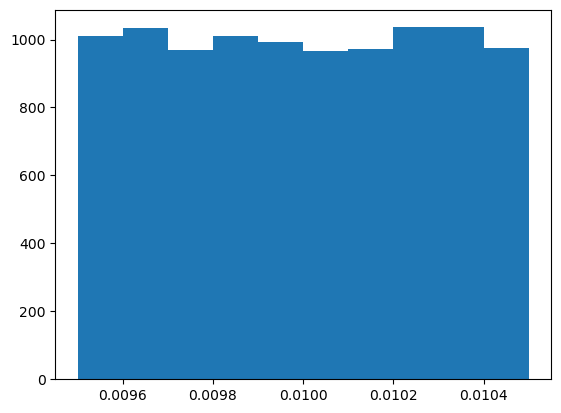

In [12]:
plt.hist(simulation_data['thickness'])
plt.show()

What is the distribution of plate thicknesses? Is it as you expected?

In [13]:
# As a rule plates are discarded if the value = (thickness^2)/area is less than 0.000015

# make a boolean (True/False) variable to indicate if each simulated plate will be discarded:

simulation_data['value'] = simulation_data['thickness']**2/simulation_data['area']
simulation_data['discard'] = simulation_data['value'] < 1.5e-5

print(simulation_data.head())

     length     width      area  small  large  thickness     value  discard
0  2.009985  3.012217  6.054512  False  False   0.010435  0.000018    False
1  2.001759  3.002237  6.009755  False  False   0.010435  0.000018    False
2  1.992384  2.989372  5.955977  False  False   0.009950  0.000017    False
3  1.988568  3.021869  6.009192  False  False   0.010232  0.000017    False
4  2.012836  2.976332  5.990868  False  False   0.010251  0.000018    False


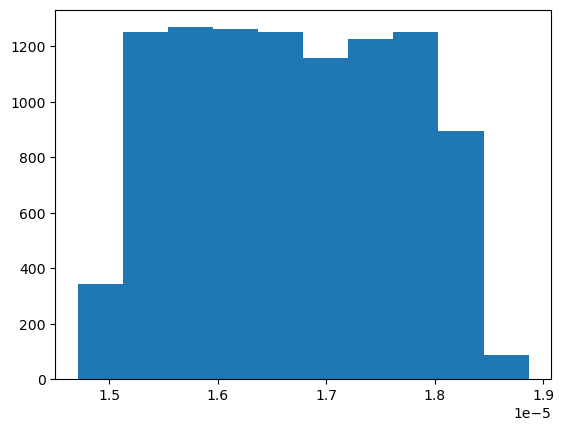

In [14]:
# visualise the distribution of the "value" (rule for discarding plates):
plt.hist(simulation_data['value'])
plt.show()

What do you think about this distribution? How would you describe it in your own words?

In [15]:
# how many plates (out of k) are discarded?
print(simulation_data['discard'].sum())
print(simulation_data['discard'].sum()/k)

110
0.011


approximately 1% of plates are discarded

Tilbage til slides!

In [16]:
# variance of the "value"
print(simulation_data['value'].var(ddof=1))

9.57228954291647e-13


In [17]:
# variance of the plate thickness:
simulation_data['thickness'].var(ddof=1)

8.394120732895102e-08

In [18]:
# theoretical variance of the plate thickness:
0.001**2 / 12

8.333333333333333e-08

In [19]:
# using error propagation to calculate variance of "value":
(0.01**2/(2**2*3))**2 * 0.01**2 + (0.01**2/(2*3**3))**2 * 0.02**2 + (2*0.01/(2*3))**2 * (0.001**2/12)

9.342421124828534e-13

In [32]:
np.random.seed(82719)

k = 10000

xA = stats.expon.rvs(scale=2, size=k)
xB = stats.expon.rvs(scale=3, size=k)
xC = stats.expon.rvs(scale=5, size=k)

df = pd.DataFrame({
"Lifetime_A":xA,
"Lifetime_B":xB,
"Lifetime_C":xC})

print(df.head())

   Lifetime_A  Lifetime_B  Lifetime_C
0    0.320960    4.895210   11.179703
1    0.491043    3.006795    4.386929
2    1.608826    1.485084    0.929437
3    2.285528    4.850018    9.774913
4    2.409813    2.420582    1.164840


In [34]:
print(df.mean())

Lifetime_A    2.003508
Lifetime_B    3.026452
Lifetime_C    5.047804
dtype: float64


   Lifetime_A  Lifetime_B  Lifetime_C  Lifetime
0    0.320960    4.895210   11.179703  0.320960
1    0.491043    3.006795    4.386929  0.491043
2    1.608826    1.485084    0.929437  0.929437
3    2.285528    4.850018    9.774913  2.285528
4    2.409813    2.420582    1.164840  1.164840




<function matplotlib.pyplot.show(close=None, block=None)>

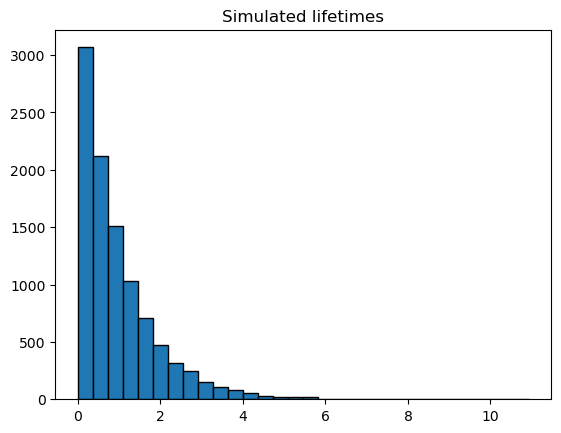

In [ ]:
df["Lifetime"] = df[["Lifetime_A","Lifetime_B","Lifetime_C"]].min(axis=1)
print(df.head())
print("\n")
plt.hist(df["Lifetime"], bins=30,edgecolor="black")
plt.title("Simulated lifetimes")
plt.show

In [45]:
print(df["Lifetime"].mean())
print(df["Lifetime"].std(ddof=1))

0.9880015386365172
0.9959225338611547


In [49]:
df["Below_one_month"] = (df["Lifetime"] <= 1)

print(df.head())
print("\n")
print(df["Below_one_month"].mean())

   Lifetime_A  Lifetime_B  Lifetime_C  Lifetime  Below_one_month
0    0.320960    4.895210   11.179703  0.320960             True
1    0.491043    3.006795    4.386929  0.491043             True
2    1.608826    1.485084    0.929437  0.929437             True
3    2.285528    4.850018    9.774913  2.285528            False
4    2.409813    2.420582    1.164840  1.164840            False


0.6391


In [50]:
print(df["Lifetime"].median())

0.6878542614451192


In [56]:
print(df["Lifetime"].quantile(0.1))

print(np.quantile(df["Lifetime"], 0.1, method="averaged_inverted_cdf"))

0.10367217182567331
0.10348342692625076


# 4.3 Various bootstrap CIs

Non-parametric bootstrap: resample with replacement from the data k times and
compute the mean of each resample. The 2.5th and 97.5th percentiles of these k means
give the 95% CI. Results vary with the random seed but are close to the result from
Exercise 2: approximately [38.38; 38.54].

In [59]:
x = np . array ([38.43 ,38.43 ,38.39 ,38.83 ,38.45 ,
38.35 ,38.43 ,38.31 ,38.32 ,38.48 ,38.50])
np.random.seed(6287)
boot = [np.random.choice(x, len(x), replace=True).mean() for _ in range(10000)]
print(np.quantile (boot, [0.025, 0.975]))

[38.38181818 38.53545455]


In [60]:
n = len(x)

simsamples = [
    np.random.normal(x.mean(), x.std(ddof=1), n).mean()
    for _ in range(10000)
]

print(np.quantile(simsamples, [0.025, 0.975]))

print(stats.t.interval(
    0.95,
    df=n-1,
    loc=x.mean(),
    scale=x.std(ddof=1) / np.sqrt(n)
))

[38.36196864 38.53004878]
(np.float64(38.35249805615088), np.float64(38.54204739839457))


In [61]:
logx = np.log(x)

simsamples = [
    np.random.lognormal(logx.mean(), logx.std(ddof=1), n).mean()
    for _ in range(10000)
]

print(np.quantile(simsamples, [0.025, 0.975]))

[38.36285854 38.53137841]


In [66]:
simQ1s = [
    np.percentile(np.random.normal(x.mean(), x.std(ddof=1), n), 25)
    for _ in range(10000)
]

print(np.quantile(simQ1s, [0.025, 0.975]))

[38.25510888 38.46577457]


In [65]:
simQ1s = [
    np.percentile(np.random.choice(x, n, replace=True), 25)
    for _ in range(10000)
]

print(np.quantile(simQ1s, [0.025, 0.975]))

[38.315 38.43 ]


# Two-sample TV data

In [67]:
x1 = np.array([1, 2, 1, 3, 2, 1, 2, 3, 1, 1])
x2 = np.array([3, 4, 2, 4, 2, 3, 2, 4, 3, 2])

np.random.seed(98273)
k = 10000

diffs = [
    np.random.choice(x1, 10, replace=True).mean()
    - np.random.choice(x2, 10, replace=True).mean()
    for _ in range(k)
]

print(np.quantile(diffs, [0.025, 0.975]))

[-1.9 -0.5]


In [69]:
print(stats.ttest_ind(x1, x2, equal_var=False))

TtestResult(statistic=np.float64(-3.157408869505305), pvalue=np.float64(0.005468240158883485), df=np.float64(17.932091487856635))


In [70]:
n = 10

diffs = [
    np.random.normal(x1.mean(), x1.std(ddof=1), n).mean()
    - np.random.normal(x2.mean(), x2.std(ddof=1), n).mean()
    for _ in range(k)
]

print(np.quantile(diffs, [0.025, 0.975]))

[-1.9542524  -0.44306079]


In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

In [107]:
np.random.seed(42)

k = 100000

xA = stats.expon.rvs(scale=2, size=k)
xB = stats.expon.rvs(scale=3, size=k)
xC = stats.expon.rvs(scale=5, size=k)

df = pd.DataFrame({"Lifetime_A":xA, "Lifetime_B":xB, "Lifetime_C":xC})

print(df.head())

   Lifetime_A  Lifetime_B  Lifetime_C
0    0.938536    2.608071    1.660525
1    6.020243    2.245800    3.068692
2    2.633491    1.297138    0.522446
3    1.825885    2.038991    2.960513
4    0.339250    1.362847    1.135013


In [ ]:
print(df.mean())
print("\n") #Mellemrum
print(xA.mean())

Lifetime_A    1.991940
Lifetime_B    3.013768
Lifetime_C    5.014187
dtype: float64


1.9919403181123698


In [126]:
df["Lifetime"] = df[["Lifetime_A", "Lifetime_B", "Lifetime_C"]].min(axis=1)
print(df.head())

   Lifetime_A  Lifetime_B  Lifetime_C  Lifetime
0    0.938536    2.608071    1.660525  0.938536
1    6.020243    2.245800    3.068692  2.245800
2    2.633491    1.297138    0.522446  0.522446
3    1.825885    2.038991    2.960513  1.825885
4    0.339250    1.362847    1.135013  0.339250


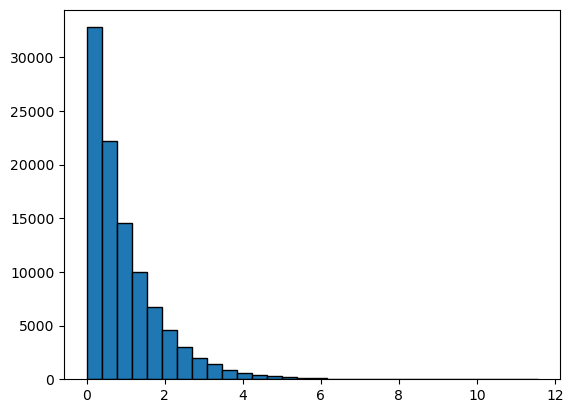

In [123]:
plt.hist(df["Lifetime"], bins=30, edgecolor="black")
plt.show()

In [129]:

print(df["Lifetime"].mean())

0.9686864811652969


In [130]:
print(df["Lifetime"].std())

0.9671047741689413


In [131]:
df["Below_1_month"] = (df["Lifetime"] <= 1)

print(df.head())

   Lifetime_A  Lifetime_B  Lifetime_C  Lifetime  Below_1_month
0    0.938536    2.608071    1.660525  0.938536           True
1    6.020243    2.245800    3.068692  2.245800          False
2    2.633491    1.297138    0.522446  0.522446           True
3    1.825885    2.038991    2.960513  1.825885          False
4    0.339250    1.362847    1.135013  0.339250           True


In [132]:
print(df["Below_1_month"].mean())

0.64338


In [138]:
print(df["Lifetime"].median())

print(np.median(df["Lifetime"]))

0.6698055494727454
0.6698055494727454


In [140]:
print(df["Lifetime"].quantile(0.10))

print(np.quantile(df["Lifetime"], 0.1, method="averaged_inverted_cdf"))

0.10337212025520584
0.1033627082409257
